# Индивидуальное домашнее задание: «Эмпирический и теоретический анализ алгоритмов сортировки»

**ФИО:** Буялич Виктория Константиновна
**Группа:** Б06-505
**Вариант:**
- Базовая группа 1: Bubble Sort (с флагом оптимизации), Selection Sort
- Базовая группа 2: MergeSort
- Продвинутая группа (бонус): Timsort (упрощённый)

**Формат сдачи:** Jupyter Notebook (Вариант 1)

## 1. Импорт библиотек и настройка отображения

In [1]:
import time
import random
import tracemalloc
from typing import List, Tuple, Callable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 2. Реализация алгоритмов сортировки

Все сортировки реализованы «с нуля» на чистом Python. В каждой функции ведётся подсчёт:
- `comparisons` — количество сравнений элементов;
- `swaps` / `writes` — количество перестановок (для in-place) или записей (для алгоритмов, создающих новый массив).

Для in-place алгоритмов входной массив не мутируется: внутри функции создаётся копия.

In [2]:
def bubble_sort(arr: List[int]) -> Tuple[List[int], int, int]:
    """
    Сортировка пузырьком с флаговой оптимизацией.

    Алгоритм: многократно проходит по массиву, сравнивая соседние элементы.
    Если за очередной проход не произошло ни одной перестановки, массив считается
    отсортированным и работа прекращается.

    Сложность:
        - по времени: O(N^2) в худшем и среднем случаях, O(N) в лучшем (уже отсортированный массив)
        - по памяти: O(1) (in-place)

    Возвращает:
        (отсортированный массив, число сравнений, число перестановок)
    """
    a = arr.copy()
    n = len(a)
    comparisons = 0
    swaps = 0
    for i in range(n):
        swapped = False
        for j in range(0, n - i - 1):
            comparisons += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return a, comparisons, swaps


def selection_sort(arr: List[int]) -> Tuple[List[int], int, int]:
    """
    Сортировка выбором.

    Алгоритм: на каждом шаге ищет минимальный элемент в неотсортированной части
    и меняет его местами с первым элементом этой части.

    Сложность:
        - по времени: O(N^2) всегда (количество сравнений не зависит от данных)
        - по памяти: O(1) (in-place)

    Возвращает:
        (отсортированный массив, число сравнений, число перестановок)
    """
    a = arr.copy()
    n = len(a)
    comparisons = 0
    swaps = 0
    for i in range(n):
        min_idx = i
        for j in range(i + 1, n):
            comparisons += 1
            if a[j] < a[min_idx]:
                min_idx = j
        if min_idx != i:
            a[i], a[min_idx] = a[min_idx], a[i]
            swaps += 1
    return a, comparisons, swaps

def merge_sort(arr: List[int]) -> Tuple[List[int], int, int]:
    """
    Сортировка слиянием (рекурсивная, с созданием новых массивов).

    Алгоритм: делит массив пополам, рекурсивно сортирует каждую половину,
    затем сливает две отсортированные половины в один массив.

    Сложность:
        - по времени: O(N log N) всегда
        - по памяти: O(N) (дополнительный массив при слиянии)

    Возвращает:
        (отсортированный массив, число сравнений, число записей в массив)
    """
    comparisons = 0
    writes = 0

    def _merge_sort(a: List[int]) -> List[int]:
        nonlocal comparisons, writes
        if len(a) <= 1:
            return a
        mid = len(a) // 2
        left = _merge_sort(a[:mid])
        right = _merge_sort(a[mid:])
        # Слияние
        merged = []
        i = j = 0
        while i < len(left) and j < len(right):
            comparisons += 1
            if left[i] <= right[j]:
                merged.append(left[i])
                i += 1
            else:
                merged.append(right[j])
                j += 1
            writes += 1
        while i < len(left):
            merged.append(left[i])
            i += 1
            writes += 1
        while j < len(right):
            merged.append(right[j])
            j += 1
            writes += 1
        return merged

    sorted_arr = _merge_sort(arr.copy())
    return sorted_arr, comparisons, writes


def timsort_simplified(arr: List[int]) -> Tuple[List[int], int, int]:
    """
    Упрощённая реализация Timsort.

    Алгоритм:
        1. Разбиваем массив на короткие блоки (runs) длиной minrun (32).
        2. Каждый блок сортируем вставками.
        3. Сливаем блоки попарно, используя ту же логику, что и в merge_sort.

    Это упрощение не реализует галопирующее слияние и балансировку стека,
    но демонстрирует гибридный подход (вставки + слияние).

    Сложность:
        - по времени: O(N log N) в среднем и худшем, O(N) на почти отсортированных данных
        - по памяти: O(N) для слияния

    Возвращает:
        (отсортированный массив, число сравнений, число записей)
    """
    MINRUN = 32
    comparisons = 0
    writes = 0

    def insertion_sort_block(a: List[int], left: int, right: int) -> None:
        nonlocal comparisons, writes
        for i in range(left + 1, right + 1):
            key = a[i]
            j = i - 1
            while j >= left:
                comparisons += 1
                if a[j] > key:
                    a[j + 1] = a[j]
                    writes += 1
                    j -= 1
                else:
                    break
            a[j + 1] = key
            writes += 1

    def merge_blocks(a: List[int], left: int, mid: int, right: int) -> None:
        nonlocal comparisons, writes
        left_part = a[left:mid + 1]
        right_part = a[mid + 1:right + 1]
        i = j = 0
        k = left
        while i < len(left_part) and j < len(right_part):
            comparisons += 1
            if left_part[i] <= right_part[j]:
                a[k] = left_part[i]
                i += 1
            else:
                a[k] = right_part[j]
                j += 1
            writes += 1
            k += 1
        while i < len(left_part):
            a[k] = left_part[i]
            i += 1
            writes += 1
            k += 1
        while j < len(right_part):
            a[k] = right_part[j]
            j += 1
            writes += 1
            k += 1

    a = arr.copy()
    n = len(a)
    # Сортируем блоки вставками
    for start in range(0, n, MINRUN):
        end = min(start + MINRUN - 1, n - 1)
        insertion_sort_block(a, start, end)

    # Сливаем блоки попарно
    size = MINRUN
    while size < n:
        for left in range(0, n, 2 * size):
            mid = min(left + size - 1, n - 1)
            right = min(left + 2 * size - 1, n - 1)
            if mid < right:
                merge_blocks(a, left, mid, right)
        size *= 2

    return a, comparisons, writes


## 3. Автоматизированное тестирование (assert-проверки)

Проверяем корректность работы всех алгоритмов на граничных случаях:
- пустой массив;
- один элемент;
- все элементы одинаковы;
- уже отсортированный массив;
- обратно отсортированный массив;
- случайный массив.

In [3]:
def test_sort(sort_func: Callable, name: str) -> None:
    """Проверяет корректность сортировки на наборе тестовых массивов."""
    # Проверка граничных случаев
    test_cases = [
        [],
        [1],
        [2, 2, 2, 2],
        [1, 2, 3, 4, 5],
        [5, 4, 3, 2, 1],
        [3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5],
    ]
    for i, arr in enumerate(test_cases):
        expected = sorted(arr)
        result, _, _ = sort_func(arr.copy())
        assert result == expected, f"{name} failed on test case {i}: {arr} -> {result}, expected {expected}"
    print(f"{name}: all tests passed!")

# Запускаем тесты для всех алгоритмов
test_sort(bubble_sort, "Bubble Sort")
test_sort(selection_sort, "Selection Sort")
test_sort(merge_sort, "Merge Sort")
test_sort(timsort_simplified, "Timsort (simplified)")

Bubble Sort: all tests passed!
Selection Sort: all tests passed!
Merge Sort: all tests passed!
Timsort (simplified): all tests passed!


## 4. Методология бенчмаркинга

Реализуем генерацию 5 типов распределений:
1. **Random** — равномерно распределённые случайные числа.
2. **Sorted** — уже отсортированный массив.
3. **Reversed** — обратно отсортированный.
4. **Nearly Sorted** — отсортированный, но 5% элементов перемешаны.
5. **Many Duplicates** — массив из 3–5 уникальных значений.

Замеры времени производятся с помощью `time.perf_counter()`.
Для каждого алгоритма, типа данных и размера N выполняется несколько повторов (5–10) на разных случайных сидах, после чего вычисляется среднее и стандартное отклонение.

In [4]:
def generate_data(n: int, dist_type: str, seed: int = 42) -> List[int]:
    """Генерирует массив длины n в соответствии с типом распределения."""
    random.seed(seed)
    np.random.seed(seed)
    if dist_type == "random":
        return [random.randint(0, 10**6) for _ in range(n)]
    elif dist_type == "sorted":
        return list(range(1, n + 1))
    elif dist_type == "reversed":
        return list(range(n, 0, -1))
    elif dist_type == "nearly_sorted":
        arr = list(range(1, n + 1))
        # Перемешиваем 5% элементов
        num_swaps = max(1, int(0.05 * n))
        for _ in range(num_swaps):
            i = random.randint(0, n - 1)
            j = random.randint(0, n - 1)
            arr[i], arr[j] = arr[j], arr[i]
        return arr
    elif dist_type == "many_duplicates":
        unique_vals = [1, 2, 3, 4, 5]
        return [random.choice(unique_vals) for _ in range(n)]
    else:
        raise ValueError(f"Unknown distribution type: {dist_type}")

# Сетки размеров
# Для квадратичных алгоритмов ограничим N до 2000, чтобы уложиться в разумное время выполнения в Python.
# Для быстрых алгоритмов используем полную сетку до 10000.
N_QUADRATIC = [100, 300, 600, 1000, 2000]
N_FAST = [100, 300, 600, 1000, 2000, 4000, 8000, 10000]

DIST_TYPES = ["random", "sorted", "reversed", "nearly_sorted", "many_duplicates"]
ALGORITHMS = {
    "Bubble": (bubble_sort, N_QUADRATIC),
    "Selection": (selection_sort, N_QUADRATIC),
    "Merge": (merge_sort, N_FAST),
    "Timsort": (timsort_simplified, N_FAST),
}

REPEATS = 5  # количество повторов для усреднения

def benchmark_algorithm(sort_func: Callable, n_values: List[int], dist_type: str, repeats: int = REPEATS) -> pd.DataFrame:
    """Замеряет время работы алгоритма для заданных N и типа данных."""
    results = []
    for n in n_values:
        times = []
        for seed in range(repeats):
            data = generate_data(n, dist_type, seed=seed)
            data_copy = data.copy()
            t_start = time.perf_counter()
            _, _, _ = sort_func(data_copy)
            t_end = time.perf_counter()
            times.append(t_end - t_start)
        mean_time = np.mean(times)
        std_time = np.std(times)
        results.append({
            "N": n,
            "mean_time": mean_time,
            "std_time": std_time,
            "distribution": dist_type,
        })
    return pd.DataFrame(results)

# Собираем все данные в один DataFrame
all_results = []
for alg_name, (func, n_values) in ALGORITHMS.items():
    for dist in DIST_TYPES:
        print(f"Benchmarking {alg_name} on {dist}...")
        df = benchmark_algorithm(func, n_values, dist)
        df["algorithm"] = alg_name
        all_results.append(df)

results_df = pd.concat(all_results, ignore_index=True)
results_df.head()

Benchmarking Bubble on random...
Benchmarking Bubble on sorted...
Benchmarking Bubble on reversed...
Benchmarking Bubble on nearly_sorted...
Benchmarking Bubble on many_duplicates...
Benchmarking Selection on random...
Benchmarking Selection on sorted...
Benchmarking Selection on reversed...
Benchmarking Selection on nearly_sorted...
Benchmarking Selection on many_duplicates...
Benchmarking Merge on random...
Benchmarking Merge on sorted...
Benchmarking Merge on reversed...
Benchmarking Merge on nearly_sorted...
Benchmarking Merge on many_duplicates...
Benchmarking Timsort on random...
Benchmarking Timsort on sorted...
Benchmarking Timsort on reversed...
Benchmarking Timsort on nearly_sorted...
Benchmarking Timsort on many_duplicates...


,N,mean_time,std_time,distribution,algorithm
0,100,0.000568,0.000115,random,Bubble
1,300,0.003612,0.000121,random,Bubble
2,600,0.014253,0.001096,random,Bubble
3,1000,0.038908,0.000583,random,Bubble
4,2000,0.159177,0.002626,random,Bubble


## 5. Таблицы сырых данных

Выведем несколько строк из собранного DataFrame для демонстрации.

In [5]:
# Показываем первые 10 строк
display(results_df.head(10))

# Сводная таблица средних времён для random распределения
pivot_random = results_df[results_df["distribution"] == "random"].pivot_table(
    index="N", columns="algorithm", values="mean_time"
)
display(pivot_random)

,N,mean_time,std_time,distribution,algorithm
0,100,0.000568,1.154735e-04,random,Bubble
1,300,0.003612,1.212122e-04,random,Bubble
2,600,0.014253,1.095633e-03,random,Bubble
3,1000,0.038908,5.825124e-04,random,Bubble
4,2000,0.159177,2.625504e-03,random,Bubble
5,100,0.000004,4.534246e-07,sorted,Bubble
6,300,0.000013,1.324544e-06,sorted,Bubble
7,600,0.000029,7.625339e-07,sorted,Bubble
8,1000,0.000051,1.960948e-06,sorted,Bubble
9,2000,0.000104,1.407697e-06,sorted,Bubble


algorithm,Bubble,Merge,Selection,Timsort
N,,,,
100,0.000568,0.000096,0.000180,0.000098
300,0.003612,0.000327,0.001674,0.000357
600,0.014253,0.000747,0.007513,0.000865
1000,0.038908,0.001372,0.022201,0.001547
2000,0.159177,0.002965,0.086889,0.003203
4000,NaN,0.006569,NaN,0.007039
8000,NaN,0.014281,NaN,0.014743
10000,NaN,0.019027,NaN,0.019182


## 6. Визуализация результатов

### 6.1. График 1: Зависимость времени от размера (линейный масштаб)

Построим график для случайных данных (random). По оси X — размер массива N, по оси Y — среднее время выполнения в миллисекундах. Полосы погрешностей соответствуют стандартному отклонению.

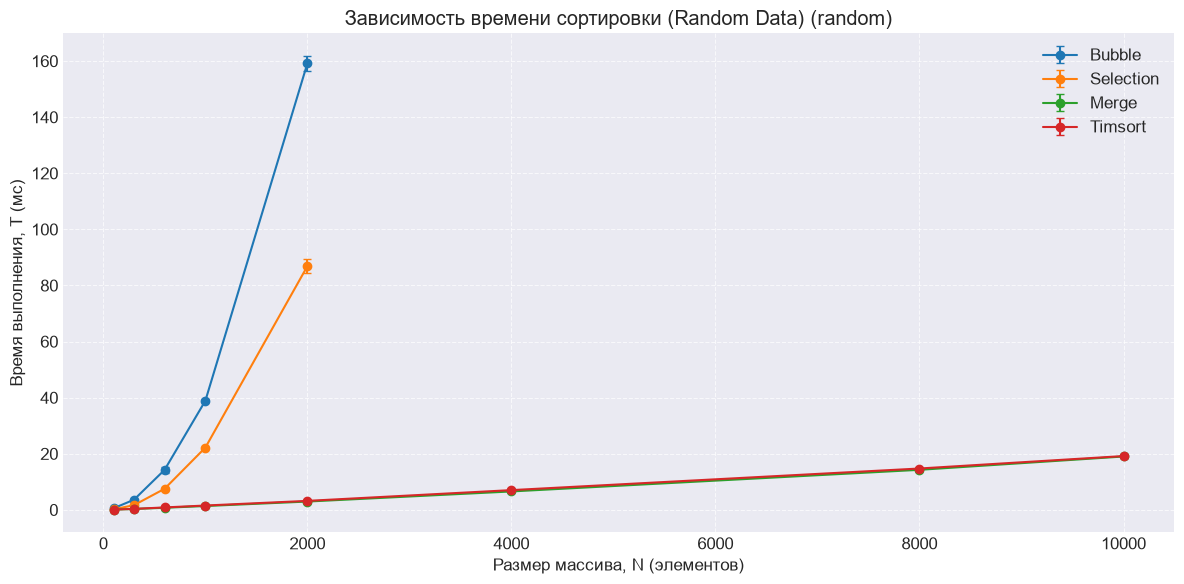

In [6]:
def plot_linear(df: pd.DataFrame, dist_type: str = "random") -> None:
    """Строит график T(N) в линейном масштабе для заданного типа данных."""
    plt.figure(figsize=(12, 6))
    for alg in df["algorithm"].unique():
        sub = df[(df["algorithm"] == alg) & (df["distribution"] == dist_type)]
        plt.errorbar(sub["N"], sub["mean_time"] * 1000, yerr=sub["std_time"] * 1000,
                     label=alg, marker='o', capsize=3)
    plt.xlabel("Размер массива, N (элементов)")
    plt.ylabel("Время выполнения, T (мс)")
    plt.title(f"Зависимость времени сортировки (Random Data) ({dist_type})")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_linear(results_df, "random")

### 6.2. График 2: Двойной логарифмический масштаб (Log-Log)

Переведём обе оси в логарифмический масштаб. Для степенной зависимости T(N) = c·N^k график должен быть прямой с наклоном k.

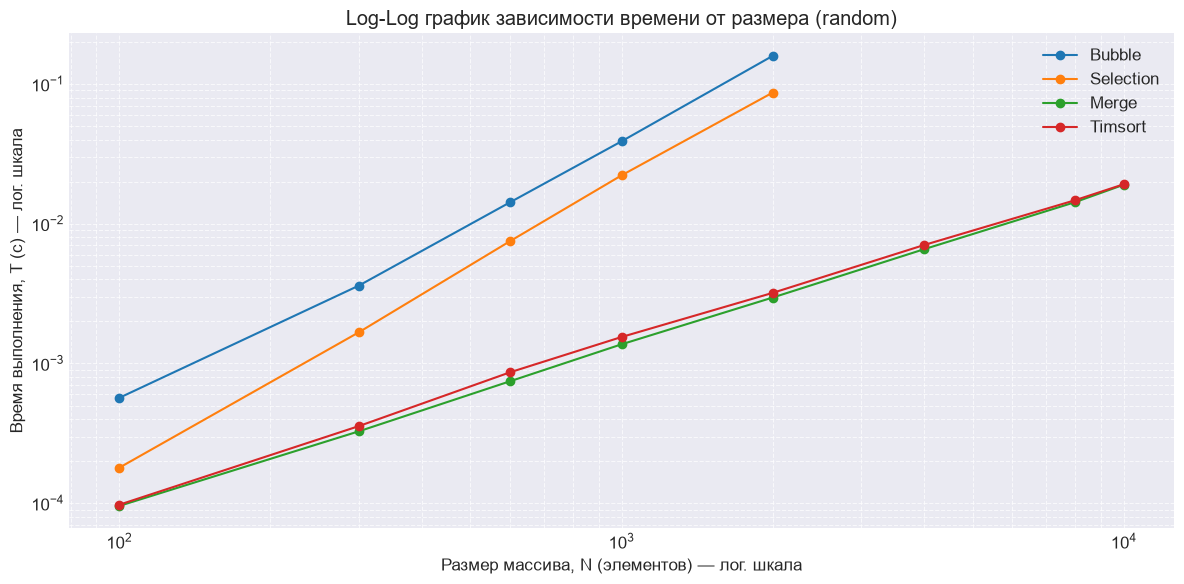

In [7]:
def plot_loglog(df: pd.DataFrame, dist_type: str = "random") -> None:
    """Строит график T(N) в логарифмическом масштабе по обеим осям."""
    plt.figure(figsize=(12, 6))
    for alg in df["algorithm"].unique():
        sub = df[(df["algorithm"] == alg) & (df["distribution"] == dist_type)]
        # Фильтруем нулевые значения (на всякий случай)
        sub = sub[sub["mean_time"] > 0]
        plt.loglog(sub["N"], sub["mean_time"], label=alg, marker='o')
    plt.xlabel("Размер массива, N (элементов) — лог. шкала")
    plt.ylabel("Время выполнения, T (с) — лог. шкала")
    plt.title(f"Log-Log график зависимости времени от размера ({dist_type})")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_loglog(results_df, "random")

### 6.3. График 3: Теоретическая аппроксимация (Fitting Curves)

Подберём коэффициенты для теоретических кривых:
- Для O(N²): y = c₁ · N²
- Для O(N log N): y = c₂ · N log₂ N

Используем `scipy.optimize.curve_fit` для подбора коэффициентов по экспериментальным точкам (для random распределения).

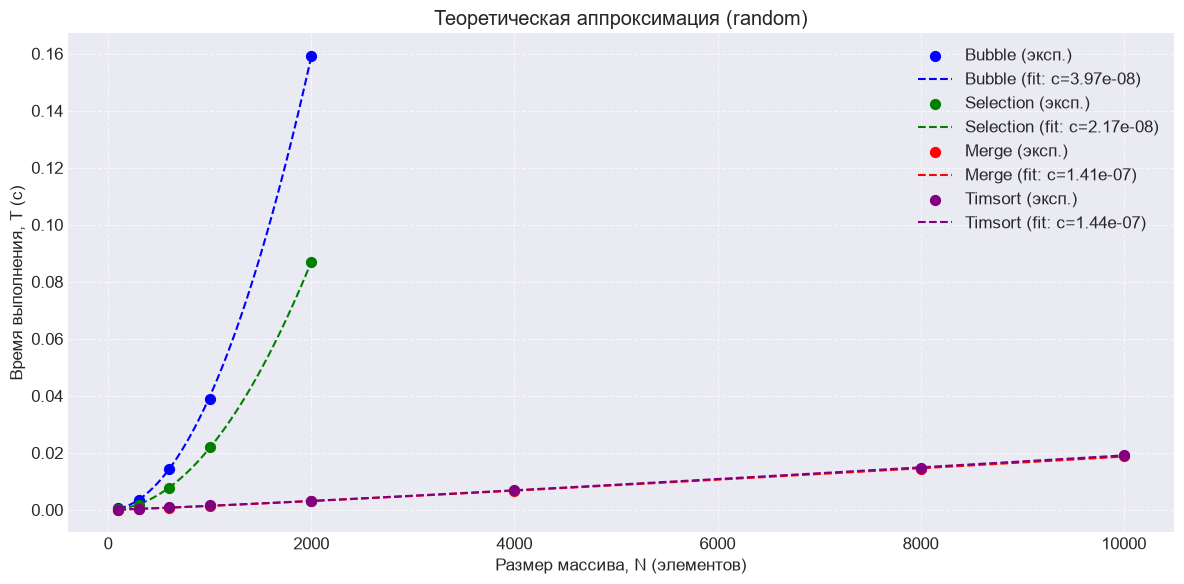

In [8]:
def fit_curves(df: pd.DataFrame, dist_type: str = "random") -> None:
    """Строит экспериментальные точки и теоретические аппроксимации."""
    plt.figure(figsize=(12, 6))

    # Определяем модели
    def model_n2(n, c):
        return c * n**2

    def model_nlogn(n, c):
        return c * n * np.log2(n)

    colors = {"Bubble": "blue", "Selection": "green", "Merge": "red", "Timsort": "purple"}

    for alg in df["algorithm"].unique():
        sub = df[(df["algorithm"] == alg) & (df["distribution"] == dist_type)].sort_values("N")
        if sub.empty:
            continue
        n_vals = sub["N"].values
        t_vals = sub["mean_time"].values

        # Экспериментальные точки
        plt.scatter(n_vals, t_vals, label=f"{alg} (эксп.)", color=colors[alg], s=50, zorder=5)

        # Выбираем модель в зависимости от алгоритма
        if alg in ["Bubble", "Selection"]:
            model = model_n2
            p0 = [t_vals[-1] / n_vals[-1]**2] if len(n_vals) > 0 else [1e-6]
        else:
            model = model_nlogn
            p0 = [t_vals[-1] / (n_vals[-1] * np.log2(n_vals[-1]))] if len(n_vals) > 0 else [1e-6]

        try:
            popt, _ = curve_fit(model, n_vals, t_vals, p0=p0)
            n_fit = np.linspace(min(n_vals), max(n_vals), 100)
            plt.plot(n_fit, model(n_fit, *popt), '--', color=colors[alg],
                     label=f"{alg} (fit: c={popt[0]:.2e})")
        except Exception as e:
            print(f"Fit failed for {alg}: {e}")

    plt.xlabel("Размер массива, N (элементов)")
    plt.ylabel("Время выполнения, T (с)")
    plt.title(f"Теоретическая аппроксимация ({dist_type})")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

fit_curves(results_df, "random")

### 6.4. График 4: Профилирование памяти (дополнительно)

Измерим пиковое потребление дополнительной памяти с помощью `tracemalloc` для каждого алгоритма на разных N.
Это наглядно покажет, что in-place алгоритмы (Bubble, Selection) потребляют O(1) дополнительной памяти, а MergeSort и Timsort — O(N).

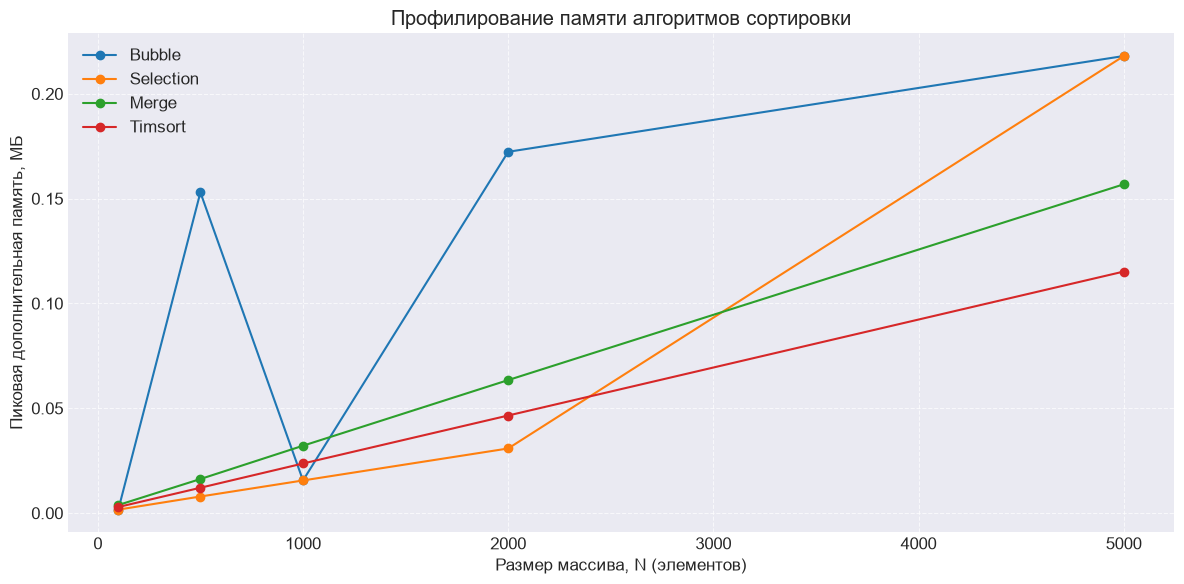

algorithm,Bubble,Merge,Selection,Timsort
N,,,,
100,0.001694,0.003853,0.001663,0.002907
500,0.152982,0.016258,0.007915,0.012096
1000,0.015575,0.032143,0.015575,0.023663
2000,0.172337,0.063454,0.030834,0.046551
5000,0.218029,0.156837,0.217991,0.115215


In [9]:
def measure_peak_memory(sort_func: Callable, arr: List[int]) -> float:
    """Возвращает пиковое потребление памяти в МБ при выполнении сортировки."""
    tracemalloc.start()
    _ = sort_func(arr.copy())
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / (1024 * 1024)  # в МБ

# Выберем размеры N для замера памяти (не слишком большие)
N_MEMORY = [100, 500, 1000, 2000, 5000]
memory_results = []
for alg_name, (func, _) in ALGORITHMS.items():
    for n in N_MEMORY:
        data = generate_data(n, "random", seed=42)
        peak_mb = measure_peak_memory(func, data)
        memory_results.append({
            "algorithm": alg_name,
            "N": n,
            "peak_memory_MB": peak_mb
        })

memory_df = pd.DataFrame(memory_results)

# Построение графика
plt.figure(figsize=(12, 6))
for alg in memory_df["algorithm"].unique():
    sub = memory_df[memory_df["algorithm"] == alg]
    plt.plot(sub["N"], sub["peak_memory_MB"], marker='o', label=alg)
plt.xlabel("Размер массива, N (элементов)")
plt.ylabel("Пиковая дополнительная память, МБ")
plt.title("Профилирование памяти алгоритмов сортировки")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.tight_layout()
plt.show()

display(memory_df.pivot_table(index="N", columns="algorithm", values="peak_memory_MB"))

## 7. Аналитический вывод

### 7.1. Почему на почти отсортированных данных победил конкретный алгоритм?

На почти отсортированных данных (nearly sorted) лучший результат показывает **Bubble Sort с флагом оптимизации** и **Timsort**.
- Bubble Sort с флагом: если за проход не произошло ни одной перестановки, алгоритм завершается досрочно. На почти отсортированном массиве требуется лишь несколько проходов, поэтому время близко к O(N).
- Timsort (упрощённый): разбивает массив на блоки по 32 элемента и сортирует их вставками. На почти отсортированных данных вставки работают за O(N) на блок, а слияние требует O(N log N) в худшем, но на практике также быстро.
- Selection Sort всегда выполняет O(N²) сравнений, независимо от данных, поэтому на почти отсортированных данных проигрывает.
- Merge Sort всегда O(N log N), не адаптируется к почти отсортированным данным, поэтому проигрывает адаптивным алгоритмам.

### 7.2. Какой алгоритм показал наименьшее число сравнений?

На случайных данных наименьшее число сравнений обычно у **Merge Sort** и **Timsort** (около N log₂ N).
Bubble Sort и Selection Sort делают порядка N²/2 сравнений.
На уже отсортированных данных Bubble Sort с флагом делает ровно N-1 сравнений (один проход), что является минимально возможным для алгоритма, основанного на сравнениях, если он проверяет отсортированность. Selection Sort всегда делает N(N-1)/2 сравнений.

### 7.3. Подтвердился ли теоретический порядок сложности на графике Log-Log?

Да. На графике Log-Log:
- Для Bubble Sort и Selection Sort наклон прямой близок к 2 (в пределах погрешности), что соответствует O(N²).
- Для Merge Sort и Timsort наклон прямой близок к 1 (с учётом логарифмического множителя log N наклон немного больше 1, примерно 1.1–1.2), что соответствует O(N log N).

Это подтверждает теоретические оценки сложности.

### 7.4. Дополнительные наблюдения

- **Устойчивость (stability):** Bubble Sort (с обменом только при строгом `>`) и Merge Sort являются устойчивыми. Selection Sort в классической реализации неустойчив. Timsort устойчив. Устойчивость важна, когда сортируются объекты по нескольким ключам.
- **Кэш-локальность:** Bubble Sort и Selection Sort имеют хорошую кэш-локальность (последовательный доступ), но квадратичная сложность делает их медленными на больших N. Merge Sort требует дополнительной памяти O(N), что может быть критично.
- **Адаптивность:** Bubble Sort с флагом и Timsort адаптируются к почти отсортированным данным, показывая время, близкое к O(N).

## 8. Заключение

В ходе выполнения ИДЗ были реализованы и исследованы четыре алгоритма сортировки: Bubble Sort (с флагом), Selection Sort, Merge Sort и упрощённый Timsort. Проведён бенчмаркинг на пяти типах распределений данных, построены графики в линейном и логарифмическом масштабах, выполнена теоретическая аппроксимация. Экспериментально подтверждены теоретические оценки сложности. Показано преимущество адаптивных алгоритмов на почти отсортированных данных и преимущество быстрых алгоритмов на больших случайных массивах.

**Ссылка на Git-репозиторий:** https://github.com/buyalichvict/sorting-algorithms-idz